In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn, Tensor
from torch.utils.data import DataLoader, TensorDataset
import rasterio
from typing import NamedTuple

from constants import SEED, DEFAULT_TILE_SIZE, CE_LOSS_IGNORE_INDEX
from grad_descent_train_eval import ExperimentRunner

np.random.seed(SEED)
torch.manual_seed(SEED)

# render figures as crisp vector graphics
try:
    from matplotlib_inline.backend_inline import set_matplotlib_formats
    set_matplotlib_formats('svg')
except ImportError:
    pass

device = (
    "cuda"
    if torch.cuda.is_available()
    else "mps"
    if torch.backends.mps.is_available()
    else "cpu"
)
print(f"Using {device} device.")

Using cuda device.


In [ ]:
class UNetParams(NamedTuple):
    embed_dim: int
    depth: int
    first_layer_num_channels: int = 16
    num_categories: int = 1

    def __str__(self):
        return f"UNet(layer1={self.first_layer_num_channels}, depth={self.depth})"


class DoubleConv(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, padding_mode='reflect'),
            nn.ReLU(),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, padding_mode='reflect'),
            nn.ReLU(),
        )

    def forward(self, X):
        return self.net(X)


class UNetDownLayer(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        self.conv = DoubleConv(in_channels, out_channels)
        self.downsample = nn.MaxPool2d(kernel_size=2)

    def forward(self, X):
        X = self.conv(X)
        return self.downsample(X), X


class UNetUpLayer(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        self.upsample = nn.ConvTranspose2d(in_channels, out_channels, kernel_size=2, stride=2)
        self.conv = DoubleConv(in_channels, out_channels)

    def forward(self, X, skip_connection_X):
        # Input: (batch, embed_dim, tile_rows, tile_cols)
        # Channels reduced by half, then concatenating the skip-connection
        # matrix brings dimensions back up to in_channels.
        # No cropping needed because of padding=1 in the convolutions, which
        # prevents the dimension of input images from being reduced.
        X = self.upsample(X)
        X = torch.cat((skip_connection_X, X), dim=1)
        X = self.conv(X)
        return X


class UNet(nn.Module):
    def __init__(self, args: UNetParams):
        super().__init__()
        # (start, layer1, ..., layerN, bottom)
        # Depth of 2 and start dim of 16 yields layer channels of: [128, 16, 32, 64]
        channels = [
            args.embed_dim,
            *[
                args.first_layer_num_channels * 2 ** i
                for i in range(args.depth)
            ]
        ]
        print("channels", channels)

        self.down_layers = nn.ModuleList()
        up_layers = []
        for i in range(len(channels) - 2):
            in_ch = channels[i]
            out_ch = channels[i + 1]
            self.down_layers.append(UNetDownLayer(in_ch, out_ch))
            up_layers.append(UNetUpLayer(out_ch * 2, out_ch))
        up_layers.reverse()  # Arrange in order of travel.
        self.up_layers = nn.ModuleList(up_layers)

        self.bottleneck = DoubleConv(channels[-2], channels[-1])
        self.head = nn.Conv2d(args.first_layer_num_channels, args.num_categories, kernel_size=1)

    def forward(self, X: Tensor):
        """
        Input: (batch, embed_dim, tile_rows, tile_cols)
        Output: (batch, num_categories, tile_rows, tile_cols)

        NOTE: nn.CrossEntropyLoss expects logits to be the second dimension.
        """
        skip_conn_results = []
        for down in self.down_layers:
            X, conv_result = down(X)
            skip_conn_results.append(conv_result)

        X = self.bottleneck(X)

        for down_result, up_layer in zip(skip_conn_results[::-1], self.up_layers):
            X = up_layer(X, down_result)

        return self.head(X)



In [3]:
# DEFAULT_BATCH_SIZE = 256
DEFAULT_BATCH_SIZE = 128

def to_data_loader(
        X: np.ndarray,
        y: np.ndarray,
        shuffle: bool = False,
        batch_size: int = DEFAULT_BATCH_SIZE
    ) -> DataLoader:
    # nn.CrossEntropyLoss expects longs.
    dataset = TensorDataset(torch.Tensor(X), torch.Tensor(y).long())
    return DataLoader(dataset, shuffle=shuffle, batch_size=batch_size)

def load_surface_fuel_data(
        embeds_file: str,
        target_file: str,
        tile_size=DEFAULT_TILE_SIZE
) -> tuple[dict[int, int], np.ndarray, np.ndarray, DataLoader, DataLoader, DataLoader]:
    """
    Returns:
    - idx_to_class: Dictionary mapping a target label index back to its
      original numeric value.
    - X_tiles: (total_tiles, bands, tile_rows, tile_cols)
    - y_tiles: (total_tiles, tile_size, tile_size)
    - Each split feature matrix has shape:
        (num_tiles_in_split, bands, tile_rows, tile_cols)
    - And target matrix:
        (num_tiles_in_split, tile_rows, tile_cols)

    Each target_matrix contains indices of surface fuels. E.g., a value of 0
    corresponds to surface fuel code 99, which is "bare ground". This mapping
    is done because nn.CrossEntropyLoss expects values in the range [0, num_categories).
    """
    with rasterio.open(embeds_file) as src:
        X = src.read()                 # (bands, rows, cols)
    with rasterio.open(target_file) as src:
        y_orig = src.read().squeeze()  # (rows, cols)

    # Map fuel categories to indices for nn.CrossEntropyLoss.
    classes, y = np.unique(y_orig, return_inverse=True)
    idx_to_class = dict(enumerate(classes))
    assert y.shape == y_orig.shape

    # Full embeddings have NaN values. Map them to 0.0, but ignore them
    # in loss calculations.
    bad_pixels = ~np.isfinite(X).all(axis=0)
    y[bad_pixels] = CE_LOSS_IGNORE_INDEX
    X = np.where(np.isfinite(X), X, 0.0)

    # Select AOI that is evenly divisible by tile dimension, then select
    # train/val/test tiles.
    bands, rows, cols = X.shape
    n_rows = rows // tile_size
    n_cols = cols // tile_size
    X_cropped = X[:, :n_rows * tile_size, :n_cols * tile_size]
    y_cropped = y[:n_rows * tile_size, :n_cols * tile_size]

    X_tiles = X_cropped.reshape(bands, n_rows, tile_size, n_cols, tile_size)
    X_tiles = X_tiles.transpose(1, 3, 0, 2, 4).reshape(-1, bands, tile_size, tile_size)
    y_tiles = y_cropped.reshape(n_rows, tile_size, n_cols, tile_size)
    y_tiles = y_tiles.transpose(0, 2, 1, 3).reshape(-1, tile_size, tile_size)

    PATTERN = np.array([[1, 1, 1],
                        [1, 2, 3]], dtype="uint8")

    tile_r = np.arange(n_rows)[:, None] % PATTERN.shape[0]
    tile_c = np.arange(n_cols)[None, :] % PATTERN.shape[1]
    tile_split = PATTERN[tile_r, tile_c].ravel()  # (total_tiles,)

    train = to_data_loader(X_tiles[tile_split == 1], y_tiles[tile_split == 1], shuffle=True)
    val = to_data_loader(X_tiles[tile_split == 2], y_tiles[tile_split == 2])
    test = to_data_loader(X_tiles[tile_split == 3], y_tiles[tile_split == 3])

    return idx_to_class, X_tiles, y_tiles, train, val, test

In [4]:
(
    idx_to_surface_fuel_cat,
    X,
    y,
    quant_train_loader,
    quant_val_loader,
    quant_test_loader
) = load_surface_fuel_data(
    "../../data/2022_foco_bbox_quant.tif",
    "../../data/surface_fuels_aligned.tif")
X.shape, y.shape

((6348, 128, 64, 64), (6348, 64, 64))

In [5]:
num_surface_fuel_labels = len(idx_to_surface_fuel_cat)
print("Number of surface fuel categories in AOI =", num_surface_fuel_labels)

Number of surface fuel categories in AOI = 30


## Quick hyperparam testing with quantized embeddings

Running two experiments at a time seems about right. Too many will crash with OOM (seen below).

Running experiment: UNet(layer1=16, depth=5)
channels [128, 16, 32, 64, 128, 256]
epoch  1  train loss 3.137  val loss 2.733  val acc 0.254  (7s)
epoch  2  train loss 2.553  val loss 2.972  val acc 0.073  (5s)
epoch  3  train loss 2.320  val loss 2.482  val acc 0.240  (5s)
epoch  4  train loss 2.224  val loss 1.887  val acc 0.378  (5s)
epoch  5  train loss 1.882  val loss 2.003  val acc 0.338  (4s)
epoch  6  train loss 1.834  val loss 2.009  val acc 0.342  (4s)
epoch  7  train loss 1.813  val loss 1.809  val acc 0.456  (5s)
epoch  8  train loss 1.713  val loss 1.585  val acc 0.511  (4s)
epoch  9  train loss 1.608  val loss 1.525  val acc 0.516  (5s)
epoch 10  train loss 1.620  val loss 1.489  val acc 0.524  (4s)
epoch 11  train loss 1.561  val loss 1.526  val acc 0.525  (4s)
epoch 12  train loss 1.535  val loss 1.516  val acc 0.531  (4s)
epoch 13  train loss 1.495  val loss 1.458  val acc 0.556  (5s)
epoch 14  train loss 1.503  val loss 1.514  val acc 0.533  (4s)
epoch 15  train loss 1

[W1127 17:09:26.147066922 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 2147483648 bytes (free: 43122688, total: 20989804544).
[W1127 17:09:26.268679567 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 2290089984 bytes (free: 538050560, total: 20989804544).
[W1127 17:09:26.268810674 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 2290089984 bytes (free: 538050560, total: 20989804544).
[W1127 17:09:26.392132626 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 3363831808 bytes (free: 538050560, total: 20989804544).
[W1127 17:09:26.392287402 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 3363831808 bytes (free: 538050560, total: 20989804544).
[W1127 17:09:26.392836914 CUDACachingAllocator.cpp:3934] memory allocation failed

OutOfMemoryError: CUDA out of memory. Tried to allocate 1024.00 MiB. GPU 0 has a total capacity of 19.55 GiB of which 513.12 MiB is free. Including non-PyTorch memory, this process has 19.03 GiB memory in use. Of the allocated memory 16.98 GiB is allocated by PyTorch, and 1.85 GiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf)

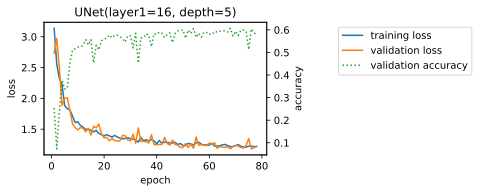

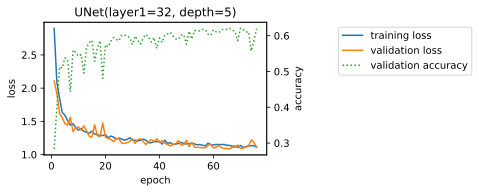

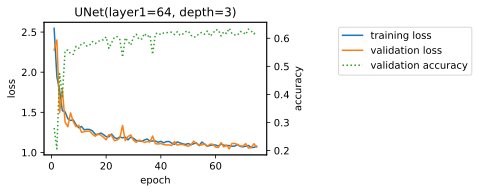

epoch 149  train loss 1.249  val loss 1.295  val acc 0.562  (4s)
epoch 150  train loss 1.260  val loss 1.233  val acc 0.593  (4s)
Running experiment: UNet(layer1=32, depth=5)
channels [128, 32, 64, 128, 256, 512]
epoch  1  train loss 2.709  val loss 2.302  val acc 0.323  (7s)
epoch  2  train loss 2.257  val loss 2.184  val acc 0.368  (7s)
epoch  3  train loss 2.162  val loss 2.106  val acc 0.389  (7s)
epoch  4  train loss 2.094  val loss 2.046  val acc 0.402  (7s)
epoch  5  train loss 2.035  val loss 1.986  val acc 0.434  (7s)
epoch  6  train loss 1.978  val loss 1.930  val acc 0.457  (6s)
epoch  7  train loss 1.920  val loss 1.867  val acc 0.473  (7s)
epoch  8  train loss 1.861  val loss 1.811  val acc 0.487  (7s)
epoch  9  train loss 1.809  val loss 1.763  val acc 0.501  (7s)
epoch 10  train loss 1.764  val loss 1.724  val acc 0.510  (7s)
epoch 11  train loss 1.722  val loss 1.682  val acc 0.520  (7s)
epoch 12  train loss 1.686  val loss 1.650  val acc 0.529  (7s)
epoch 13  train los

,Classifier,Loss (val),Acc (val),Epochs,Param count
0,"UNet(layer1=16, depth=5)",1.233,0.5937,150,1959598
1,"UNet(layer1=32, depth=5)",1.1497,0.6111,150,7797054


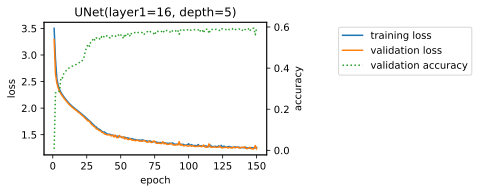

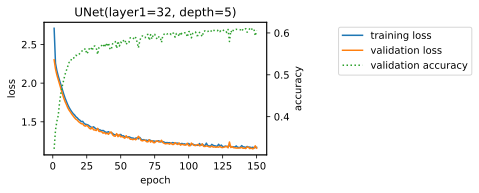

In [ ]:
runner1_1 = (
    ExperimentRunner(UNet)
        .with_lr(0.01)
        .with_patience(10)
        .with_epochs(150)
        .with_data(quant_train_loader, quant_val_loader)
        .add_experiments(
            UNetParams(
                embed_dim=128,
                num_categories=num_surface_fuel_labels,
                first_layer_num_channels=16,
                depth=5,
            ),
            UNetParams(
                embed_dim=128,
                num_categories=num_surface_fuel_labels,
                first_layer_num_channels=32,
                depth=5,
            ),
        ).with_plots()
)

runner_results1_1 = runner1_1.run(verbosity=1)
runner_results1_1

In [ ]:
runner1_2 = (
    ExperimentRunner(UNet)
        .with_lr(0.001)
        .with_patience(10)
        .with_epochs(150)
        .with_data(quant_train_loader, quant_val_loader)
        .add_experiments(
            UNetParams(
                embed_dim=128,
                num_categories=num_surface_fuel_labels,
                first_layer_num_channels=16,
                depth=5,
            ),
            UNetParams(
                embed_dim=128,
                num_categories=num_surface_fuel_labels,
                first_layer_num_channels=32,
                depth=5,
            ),
        ).with_plots()
)

runner_results1_2 = runner1_2.run(verbosity=1)
runner_results1_2

Running experiment: UNet(layer1=16, depth=5)
channels [128, 16, 32, 64, 128, 256]
epoch  1  train loss 3.502  val loss 3.290  val acc 0.007  (7s)
epoch  2  train loss 2.913  val loss 2.638  val acc 0.280  (4s)
epoch  3  train loss 2.556  val loss 2.471  val acc 0.280  (4s)
epoch  4  train loss 2.428  val loss 2.377  val acc 0.281  (4s)
epoch  5  train loss 2.353  val loss 2.316  val acc 0.291  (4s)
epoch  6  train loss 2.298  val loss 2.268  val acc 0.354  (4s)
epoch  7  train loss 2.255  val loss 2.229  val acc 0.352  (4s)
epoch  8  train loss 2.218  val loss 2.193  val acc 0.372  (4s)
epoch  9  train loss 2.183  val loss 2.161  val acc 0.380  (4s)
epoch 10  train loss 2.151  val loss 2.129  val acc 0.389  (4s)
epoch 11  train loss 2.120  val loss 2.096  val acc 0.395  (4s)
epoch 12  train loss 2.089  val loss 2.069  val acc 0.401  (4s)
epoch 13  train loss 2.064  val loss 2.046  val acc 0.404  (4s)
epoch 14  train loss 2.041  val loss 2.023  val acc 0.409  (4s)
epoch 15  train loss 2

**These results $\uparrow$ were added to the cell above's output.**

Running experiment: UNet(layer1=64, depth=3)
channels [128, 64, 128, 256]
epoch  1  train loss 2.591  val loss 2.142  val acc 0.402  (10s)
epoch  2  train loss 2.021  val loss 1.865  val acc 0.442  (8s)
epoch  3  train loss 1.812  val loss 1.836  val acc 0.409  (8s)
epoch  4  train loss 1.727  val loss 1.639  val acc 0.488  (8s)
epoch  5  train loss 1.654  val loss 1.562  val acc 0.510  (8s)
epoch  6  train loss 1.647  val loss 1.513  val acc 0.518  (8s)
epoch  7  train loss 1.569  val loss 1.530  val acc 0.512  (8s)
epoch  8  train loss 1.504  val loss 1.455  val acc 0.537  (8s)
epoch  9  train loss 1.476  val loss 1.413  val acc 0.553  (8s)
epoch 10  train loss 1.469  val loss 1.424  val acc 0.543  (8s)
epoch 11  train loss 1.432  val loss 1.387  val acc 0.564  (8s)
epoch 12  train loss 1.417  val loss 1.368  val acc 0.558  (8s)
epoch 13  train loss 1.379  val loss 1.375  val acc 0.562  (8s)
epoch 14  train loss 1.375  val loss 1.522  val acc 0.482  (8s)
epoch 15  train loss 1.356  v

[W1127 22:46:25.647595269 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 2147483648 bytes (free: 1817313280, total: 20989804544).
[W1127 22:46:25.743440860 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 2290089984 bytes (free: 1028784128, total: 20989804544).
[W1127 22:46:25.743589893 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 2290089984 bytes (free: 1028784128, total: 20989804544).
[W1127 22:46:26.886899763 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 3363831808 bytes (free: 1028784128, total: 20989804544).
[W1127 22:46:26.887085735 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 3363831808 bytes (free: 1028784128, total: 20989804544).
[W1127 22:46:26.887621514 CUDACachingAllocator.cpp:3934] memory allocation 

OutOfMemoryError: CUDA out of memory. Tried to allocate 1024.00 MiB. GPU 0 has a total capacity of 19.55 GiB of which 979.12 MiB is free. Including non-PyTorch memory, this process has 18.57 GiB memory in use. Of the allocated memory 16.98 GiB is allocated by PyTorch, and 1.40 GiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf)

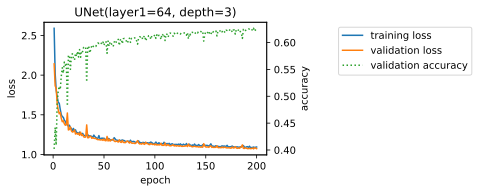

In [ ]:
runner1_3 = (
    ExperimentRunner(UNet)
        .with_lr(0.001)
        .with_patience(10)
        .with_epochs(200)
        .with_data(quant_train_loader, quant_val_loader)
        .add_experiments(
            UNetParams(
                embed_dim=128,
                num_categories=num_surface_fuel_labels,
                first_layer_num_channels=64,
                depth=3,
            ),
        ).with_plots()
)

runner_results1_3 = runner1_3.run(verbosity=1)
runner_results1_3

Running experiment: UNet(layer1=256, depth=3)
channels [128, 256, 512, 1024]
epoch  1  train loss 2.054  val loss 1.804  val acc 0.399  (37s)
epoch  2  train loss 1.575  val loss 1.434  val acc 0.551  (35s)
epoch  3  train loss 1.456  val loss 1.480  val acc 0.510  (35s)
epoch  4  train loss 1.394  val loss 1.424  val acc 0.503  (35s)
epoch  5  train loss 1.349  val loss 1.297  val acc 0.581  (35s)
epoch  6  train loss 1.320  val loss 1.277  val acc 0.584  (35s)
epoch  7  train loss 1.288  val loss 1.367  val acc 0.510  (35s)
epoch  8  train loss 1.269  val loss 1.266  val acc 0.579  (35s)
epoch  9  train loss 1.247  val loss 1.258  val acc 0.573  (35s)
epoch 10  train loss 1.250  val loss 1.246  val acc 0.575  (35s)
epoch 11  train loss 1.225  val loss 1.350  val acc 0.513  (35s)
epoch 12  train loss 1.223  val loss 1.194  val acc 0.597  (35s)
epoch 13  train loss 1.198  val loss 1.189  val acc 0.597  (35s)
epoch 14  train loss 1.213  val loss 1.190  val acc 0.599  (35s)
epoch 15  tra

,Classifier,Loss (val),Acc (val),Epochs,Param count
0,"UNet(layer1=256, depth=3)",1.0018,0.6459,139,30061854


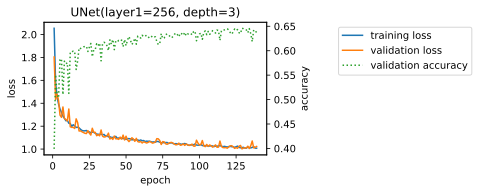

In [6]:
runner1_4 = (
    ExperimentRunner(UNet)
        .with_lr(0.001)
        .with_patience(10)
        .with_epochs(200)
        .with_data(quant_train_loader, quant_val_loader)
        .add_experiments(
            UNetParams(
                embed_dim=128,
                num_categories=num_surface_fuel_labels,
                first_layer_num_channels=256,
                depth=3,
            ),
        ).with_plots()
)

runner_results1_4 = runner1_4.run(verbosity=1)
runner_results1_4

### Render quantized embeddings

In [10]:
idx_to_fuel_code_lookup = torch.zeros(max(idx_to_surface_fuel_cat.keys()) + 1, dtype=torch.long, device=device)
for k, v in idx_to_surface_fuel_cat.items():
    idx_to_fuel_code_lookup[k] = v

In [7]:
model = runner1_4.experiment_results[0].model.to(device)

In [8]:
val_sample_X, val_sample_y = next(iter(quant_val_loader))
val_sample_X, val_sample_y = val_sample_X[:1].to(device), val_sample_y[:1].to(device)

In [11]:
with torch.no_grad():
    predicted_tile = model(val_sample_X).argmax(dim=1)

predicted_surface_fuel_codes_full = idx_to_fuel_code_lookup[predicted_tile]
true_surface_fuel_codes_full = idx_to_fuel_code_lookup[val_sample_y]

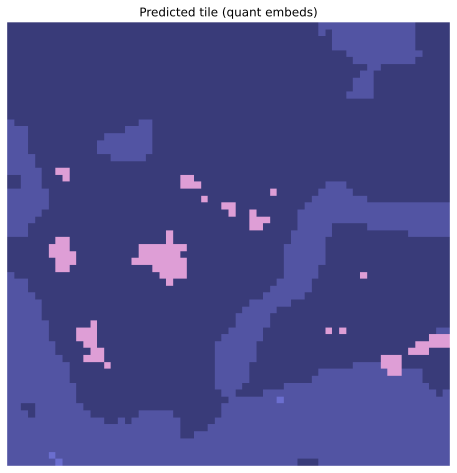

In [15]:
plt.figure(figsize=(10, 8))
plt.imshow(predicted_surface_fuel_codes_full.squeeze().cpu(), cmap="tab20b")
plt.title("Predicted tile (quant embeds)")
plt.axis("off")
plt.show();

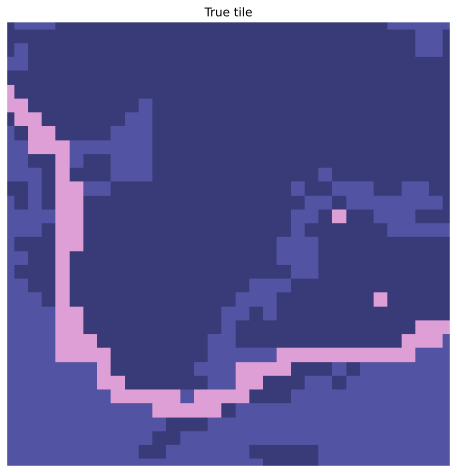

In [14]:
plt.figure(figsize=(10, 8))
plt.imshow(true_surface_fuel_codes_full.squeeze().cpu(), cmap="tab20b")
plt.title("True tile")
plt.axis("off")
plt.show();